## Tentative d'affichage d'image 

Pour valider que données sont représentées comme valeurs de pixels dans le fichier csv des données

_importations_

In [1]:
import pandas as pnd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split # pip install requests scikit-learn
import tensorflow as tf # pip install requests tensorflow
import keras # pip install requests keras

I0000 00:00:1793374041.643274  176957 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793374041.643550  176957 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793374041.667748  176957 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793374042.265741  176957 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

### Définition de la largeur et longueur de l'image et chargement de l'image

In [2]:
tf.config.set_visible_devices([], 'GPU')

LONGUEUR_IMAGE = 28
LARGEUR_IMAGE = 28

observations_entrainement = pnd.read_csv('../datas/fichiersLabAnalyse_images/fashion-mnist_train.csv')

E0000 00:00:1793374042.336694  176957 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Afficher l'image à partir des pixels décrits dans le fichier csv

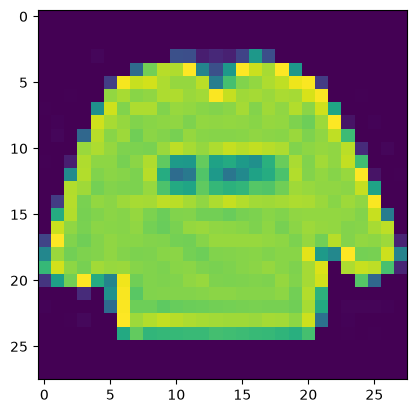

In [3]:
X = np.array(observations_entrainement.iloc[:, 1:])

premiereImage = X[0]
premiereImage = premiereImage.reshape([LONGUEUR_IMAGE,LARGEUR_IMAGE])
plt.imshow(premiereImage)
plt.show()

## Préparation des données d'apprentissage

### Créer les jeux d’apprentissage et de tests 

Créer des catégories à l'aide du module Keras. Puis répartir des données d'entrainement en données d'apprentissage et données de validation (80% de donnée d'apprentissage et 20% de donnée de validation)

In [4]:
y = keras.utils.to_categorical(np.array(observations_entrainement.iloc[:,0]))
X_apprentissage, X_validation, y_apprentissage, y_validation = train_test_split(X, y, test_size=0.2, random_state=13)

Redimensionner les images au format 28*28 et réaliser un scaling sur les données des pixels

In [5]:
X_apprentissage = X_apprentissage.reshape(X_apprentissage.shape[0], 
                                          LARGEUR_IMAGE, 
                                          LONGUEUR_IMAGE, 1)
X_apprentissage = X_apprentissage.astype('float32')
X_apprentissage /= 255

X_validation = X_validation.reshape(X_validation.shape[0], 
                                    LARGEUR_IMAGE, 
                                    LONGUEUR_IMAGE, 1)
X_validation = X_validation.astype('float32')
X_validation /= 255

Préparation des données tests

In [6]:
observations_test = pnd.read_csv('../datas/fichiersLabAnalyse_images/fashion-mnist_train.csv')
X_test = np.array(observations_test.iloc[:, 1:])
y_test = tf.keras.utils.to_categorical(np.array(observations_test.iloc[:, 0]))
X_test = X_test.reshape(X_test.shape[0], 
                        LARGEUR_IMAGE, 
                        LONGUEUR_IMAGE, 1)
X_test = X_test.astype('float32')
X_test /= 255

## Configuration d'un réseau de neurones

Liste des configurations : 
- Une couche de convolution de 32 filtres de taille 3x3 avec une fonction d’activation de type ReLU
- Un pooling composé d’un filtre de 2x2
- Une phase de flatten (mise en colonne des résultats du pooling)
- Un réseau de neurones complètement connecté de 128 neurones avec une fonction d’activation de type ReLU
- Un dernier réseau de neurones complètement connecté comportant 10 neurones et une fonction - d’activation de type Softmax correspondant aux 10 catégories d’images à prédire

In [7]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Input
from keras.layers import Conv2D, MaxPooling2D

# On spécifie les dimensions de l'image d'entrée
dimentionImage = (LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

# On crée le réseau de neurones couche par couche
reseauNeurone1Convolution = Sequential()

# Ajout de la couche d'entrée
reseauNeurone1Convolution.add(Input(shape=dimentionImage))

#1- Ajout de la couche de convolution comportant
# 32 filtres de de taille 3x3 (Kernel) parcourant l'image
# Une fonction d'activation de type ReLU (Rectified Linear Activation)
# Une image d'entrée de 28px * 28 px 
reseauNeurone1Convolution.add(Conv2D(32, 
                                     kernel_size=(3, 3), 
                                     activation='relu'))

#2- Définition de la fonction de pooling avec une fenêtre de 2px sur 2 px
reseauNeurone1Convolution.add(MaxPooling2D(pool_size=(2, 2)))

#3- Ajout d'une fonction d'ignorance
reseauNeurone1Convolution.add(Dropout(0.2))

#5 - On transforme en une seule ligne
reseauNeurone1Convolution.add(Flatten())

#6 - Ajout d'un réseau de neurones composé de 128 neurones avec 
# une fonction d'activation de type ReLU
reseauNeurone1Convolution.add(Dense(128, activation='relu'))

#7 - Ajout d'un réseau de neurones composé de 10 neurones avec une 
# fonction d'activation de type softmax
reseauNeurone1Convolution.add(Dense(10, activation='softmax'))

## Compilser et réaliser l'apprentissage du réseau

In [8]:
reseauNeurone1Convolution.compile(loss=keras.losses.categorical_crossentropy, 
                                  optimizer=tf.keras.optimizers.Adam(), 
                                  metrics=['accuracy'])

Paramétrer l'apprentissage ainsi :

- 10 passages complets du jeu de données à travers le réseau de neurones (epoch)
- 256 images traitées à la fois (batch_size)
- Un affichage des logs d’apprentissage dans la console (verbose=1)
- La validation du modèle est basée sur les images et labels de validation définis plus en amont de ce chapitre (80 % de données d’apprentissage et 20 % de données de validation)

In [9]:
historique_apprentissage = reseauNeurone1Convolution.fit(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256,
    epochs=10,
    verbose=1,
    validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.8101 - loss: 0.5479 - val_accuracy: 0.8628 - val_loss: 0.3849
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.8763 - loss: 0.3504 - val_accuracy: 0.8841 - val_loss: 0.3277
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.8891 - loss: 0.3142 - val_accuracy: 0.8851 - val_loss: 0.3153
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.8964 - loss: 0.2885 - val_accuracy: 0.8972 - val_loss: 0.2922
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9042 - loss: 0.2692 - val_accuracy: 0.9004 - val_loss: 0.2784
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9103 - loss: 0.2521 - val_accuracy: 0.9023 - val_loss: 0.2752
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9154 - loss: 0.2391 - val_accuracy: 0.9043 - val_loss: 0.2668
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.9183 - loss: 0.2267 - val_accu

### Évaluation du modèle d’apprentissage sur les données de tests afin de déterminer la précision d’apprentissage

In [10]:
evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Précision:', evaluation[1])

Erreur: 0.20248129963874817
Précision: 0.9267833232879639


Nous avons une précision de classification de 93,25 % avec un taux d’erreur de 19,20 %.

### Affichage de graphique des courbes de précision et d’erreur après chaque passage complet du jeu de données à travers le réseau de neurones (epoch)

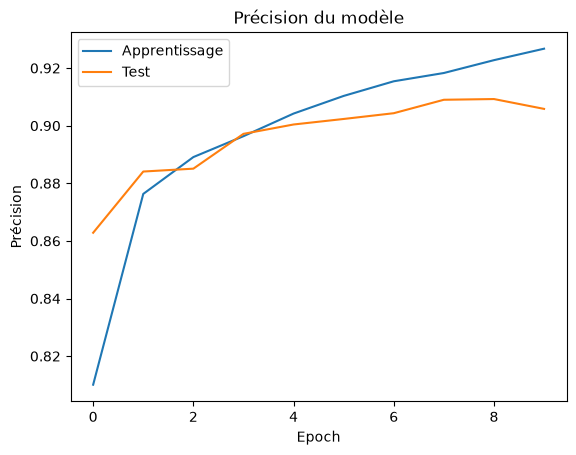

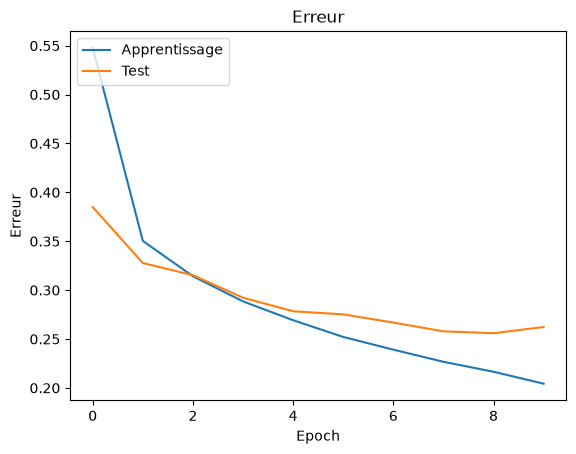

In [11]:
plt.plot(historique_apprentissage.history['accuracy'])
plt.plot(historique_apprentissage.history['val_accuracy'])
plt.title('Précision du modèle')
plt.ylabel('Précision')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()

plt.plot(historique_apprentissage.history['loss'])
plt.plot(historique_apprentissage.history['val_loss'])
plt.title('Erreur')
plt.ylabel('Erreur')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()

Nous observons que l'erreur diminue par passage complet du jeu de données à travers le réseau de neurones et la précison augmente par passage complet du jeu de données à travers le réseau de neurones.

## Augmentation du nombre d’images du jeu d’apprentissage

Avec la fonction ImageDataGenerator du module Keras

In [12]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

generateur_images = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=8,
    width_shift_range=0.08,
    shear_range=0.3,
    height_shift_range=0.08,
    zoom_range=0.08)

### Générer de nouvelles images et procéder à un nouvel apprentissage.

In [13]:
nouvelles_images_apprentissage = generateur_images.flow(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256)

nouvelles_images_validation = generateur_images.flow(
    X_validation, 
    y_validation,
    batch_size=256)

historique_apprentissage = reseauNeurone1Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000//256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000//256,
    verbose=1 )

evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision:', evaluation[1])

Epoch 1/50
  1/187 ━━━━━━━━━━━━━━━━━━━━ 37s 204ms/step - accuracy: 0.7812 - loss: 0.6427

I0000 00:00:1793374076.173692  176957 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


187/187 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.8274 - loss: 0.4647 - val_accuracy: 0.8464 - val_loss: 0.4127
Epoch 2/50
  1/187 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8398 - loss: 0.4621

/home/cano/repos/420-5G4-ML-nbc/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8398 - loss: 0.4621 - val_accuracy: 0.8523 - val_loss: 0.4079
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.8487 - loss: 0.4097 - val_accuracy: 0.8484 - val_loss: 0.4093
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8359 - loss: 0.4130 - val_accuracy: 0.8512 - val_loss: 0.4057
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - accuracy: 0.8562 - loss: 0.3876 - val_accuracy: 0.8559 - val_loss: 0.3947
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8633 - loss: 0.3303 - val_accuracy: 0.8533 - val_loss: 0.3883
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.8603 - loss: 0.3794 - val_accuracy: 0.8612 - val_loss: 0.3685
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8672 - loss: 0.3104 - val_accuracy: 0.8659 - val_loss: 0.3640
Epoch 9/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.8659 - loss: 0.3623 - val_accuracy: 0.8702 - 

## Sauvegarde du modèle

In [14]:
model_json = reseauNeurone1Convolution.to_json() 
with open("../modele/modele.json", "w") as json_file:
    json_file.write(model_json)
    
reseauNeurone1Convolution.save_weights("../modele/modele.weights.h5")
print("Modèle sauvegardé !")

Modèle sauvegardé !


## Augmentation de la performance du modèle avec 4 couches de convolution

In [15]:
from keras.layers import BatchNormalization

reseauNeurones4Convolution = Sequential()

reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=dimentionImage))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Flatten())
reseauNeurones4Convolution.add(Dense(512, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(128, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(10, activation='softmax'))

/home/cano/repos/420-5G4-ML-nbc/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Lancement de l'apprentissage du modèle à performance augmentée

In [16]:
reseauNeurones4Convolution.compile(loss=keras.losses.categorical_crossentropy, 
                                  optimizer=tf.keras.optimizers.Adam(), 
                                  metrics=['accuracy'])

historique_apprentissage = reseauNeurones4Convolution.fit(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256,
    epochs=10,
    verbose=1,
    validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 12s 57ms/step - accuracy: 0.7372 - loss: 0.7616 - val_accuracy: 0.3512 - val_loss: 2.3984
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.8433 - loss: 0.4388 - val_accuracy: 0.5340 - val_loss: 1.7170
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.8699 - loss: 0.3656 - val_accuracy: 0.7983 - val_loss: 0.5359
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.8830 - loss: 0.3305 - val_accuracy: 0.8884 - val_loss: 0.3155
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.8918 - loss: 0.3034 - val_accuracy: 0.9020 - val_loss: 0.2679
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 10s 56ms/step - accuracy: 0.8993 - loss: 0.2831 - val_accuracy: 0.9021 - val_loss: 0.2826
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 56ms/step - accuracy: 0.9036 - loss: 0.2677 - val_accuracy: 0.9071 - val_loss: 0.2540
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 11s 56ms/step - accuracy: 0.9069 - loss: 0.2590 - 

Évaluation des résultats du modèle plus performant

In [17]:
evaluation = reseauNeurones4Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Précision:', evaluation[1])

Erreur: 0.18563774228096008
Précision: 0.9320833086967468


Nous avons une précision de classification de 93,03 % avec un taux d’erreur de 18,58 %. le taux d'erreur a légèrement diminué.

Utilisation d'encore plus de données

In [18]:
historique_apprentissage = reseauNeurones4Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000//256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000//256,
    verbose=1 )

evaluation = reseauNeurones4Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision:', evaluation[1])

Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 11s 55ms/step - accuracy: 0.8543 - loss: 0.4078 - val_accuracy: 0.8770 - val_loss: 0.3268
Epoch 2/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8555 - loss: 0.4031 - val_accuracy: 0.8674 - val_loss: 0.3612
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 10s 54ms/step - accuracy: 0.8671 - loss: 0.3677 - val_accuracy: 0.8891 - val_loss: 0.3061
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8711 - loss: 0.3357 - val_accuracy: 0.8871 - val_loss: 0.3136
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 10s 54ms/step - accuracy: 0.8761 - loss: 0.3452 - val_accuracy: 0.8819 - val_loss: 0.3236
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8359 - loss: 0.3724 - val_accuracy: 0.8838 - val_loss: 0.3175
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 10s 53ms/step - accuracy: 0.8794 - loss: 0.3306 - val_accuracy: 0.8909 - val_loss: 0.2893
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8516 - loss: 0.3646 - val_accu